# Laboratorio Evaluado: WBCD y Evaluación Multimodelo

**Reto Autónomo: Clínica Oncológica**

Eres el Consultor IA de un hospital. El dataset WBCD contiene radios y perímetros de células. Debes entrenar k-NN y Árboles de Decisión, y validar qué pasa si no escalas los datos.

## 1. Carga de Datos y Exploración

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Carga el dataset WBCD desde UCI (Wisconsin Diagnostic Breast Cancer)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# El dataset no tiene cabecera. La columna 0 es ID, la columna 1 es el Diagnóstico (M/B), y las demás son 30 características.
column_names = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
df_wbcd = pd.read_csv(url, header=None, names=column_names)
display(df_wbcd.head())

,id,diagnosis,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Preprocesamiento

In [2]:
# Convierte la columna de diagnosis (M/B) a binario (Maligno='M'->1, Benigno='B'->0)
df_wbcd['diagnosis'] = df_wbcd['diagnosis'].map({'M': 1, 'B': 0})

# Separa en X (features) e y (target). Excluimos la columna 'id' y 'diagnosis'.
X = df_wbcd.drop(columns=['id', 'diagnosis'])
y = df_wbcd['diagnosis']

# Haz el train_test_split (80% train, 20% test, con estratificación y random_state)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Entrenamiento: {X_train.shape[0]} muestras. Prueba: {X_test.shape[0]} muestras.")

Entrenamiento: 455 muestras. Prueba: 114 muestras.


## 3. Escalamiento (Solo para k-NN)

In [3]:
# Aplica StandardScaler a X_train y X_test.
# Recuerda: .fit_transform() en train, y solo .transform() en test.
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)
print("¡Datos escalados correctamente para k-NN!")

¡Datos escalados correctamente para k-NN!


## 4. Modelado y Matrices de Confusión

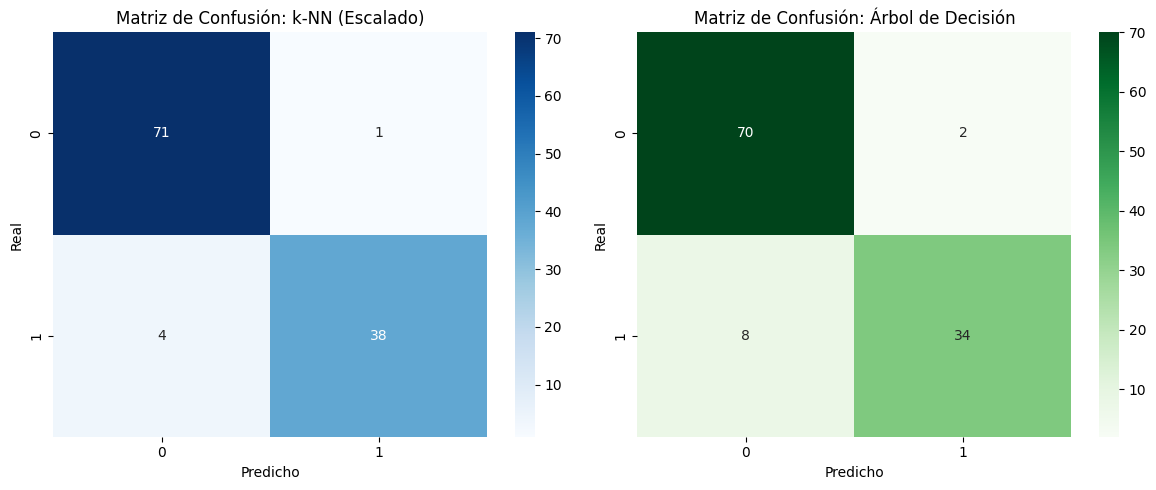

Reporte k-NN:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97        72
           1       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114

Reporte Árbol de Decisión:
              precision    recall  f1-score   support

           0       0.90      0.97      0.93        72
           1       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114



In [4]:
# Entrena un KNeighborsClassifier(n_neighbors=5) usando los datos escalados
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_esc, y_train)
pred_knn = knn.predict(X_test_esc)

# Entrena un DecisionTreeClassifier(max_depth=4) usando los datos originales (sin escalar)
arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_train, y_train)
pred_arbol = arbol.predict(X_test)

# Imprime y grafica las matrices de confusión para ambos
cm_knn = confusion_matrix(y_test, pred_knn)
cm_arbol = confusion_matrix(y_test, pred_arbol)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matriz de Confusión: k-NN (Escalado)')
axes[0].set_xlabel('Predicho')
axes[0].set_ylabel('Real')

sns.heatmap(cm_arbol, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('Matriz de Confusión: Árbol de Decisión')
axes[1].set_xlabel('Predicho')
axes[1].set_ylabel('Real')

plt.tight_layout()
plt.show()

print("Reporte k-NN:")
print(classification_report(y_test, pred_knn))
print("Reporte Árbol de Decisión:")
print(classification_report(y_test, pred_arbol))

## Evaluación Teórica / Decisión de Negocios

1. En este escenario médico, ¿qué implica un Error Tipo II (Falso Negativo) y por qué cuesta vidas?
2. ¿Por qué crees que el Árbol de Decisión no falló estrepitosamente incluso si no hubieses escalado los datos?

*Escribe tu respuesta aquí:*

**Respuestas:**
1. **Falso Negativo (Error Tipo II):** Significa que el modelo predice que el tumor es benigno (0) cuando en realidad el paciente tiene un tumor maligno (1). Esto cuesta vidas porque al paciente se le daría un diagnóstico de falsa seguridad, retrasando la detección y el tratamiento oncológico crítico.
2. **Inmunidad al escalamiento del Árbol de Decisión:** Los árboles de decisión se basan en particiones o umbrales lógicos (*if-else*) sobre los valores individuales de cada característica. Al algoritmo solo le importa el orden relativo de los datos para encontrar el punto de corte óptimo (impureza de Gini o Entropía), por lo que la magnitud absoluta o el tamaño de la escala de la variable no afectan la lógica de sus divisiones.